# Task 2 missing-value EDA

คำถาม: Task 2 มีทางได้คะแนนเพิ่มจากค่าว่างแบบ Task 3 ไหม README บอกว่า feature ในแต่ละคลาสแทบไม่สัมพันธ์กัน (Spearman สูงสุด 0.04) ถ้าจริงการเติมค่าก็ไม่ช่วย notebook นี้ตรวจด้วยตัวเลข (R², บล็อกความสัมพันธ์) และดูว่าการที่ naive Bayes ข้ามค่าว่าง กับ CatBoost ที่จัดการค่าว่างเอง ต่างกันตรงไหน

ข้อมูล: `train.csv` (104,000 แถว มี label ครบ) + OOF ของโมเดลปัจจุบัน (NB 0.6 × CatBoost 0.4, `outputs/experiments/task2_oof.csv` จาก `Task2/eda/make_oof.py`: StratifiedKFold 3, seed 342, 12 threads) ไม่ใช้ test

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from catboost import CatBoostClassifier
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import binom, chi2_contingency, norm, spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, r2_score, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA                       # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import TASK2_BAYES_WEIGHT, _prepare      # NB share in the blend (0.6) and the pipeline's column prep
from pis.task2_naive_bayes import SmoothNaiveBayes, geometric_blend

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'

def tidy(ax, grid='y'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the OOF

ต้องได้ Macro F1 0.7567 ตาม README และแถวต้องเรียงตรงกับ `train.csv`

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '02_multiclass_classification' / 'train.csv')
o = pd.read_csv('outputs/experiments/task2_oof.csv')     # current model (NB x CatBoost blend), 3-fold OOF
assert tr['segment'].notna().all()
assert (tr['player_id'].to_numpy() == o['player_id'].to_numpy()).all(), 'OOF row order differs from train.csv'
assert (tr['segment'].to_numpy() == o['target'].to_numpy()).all()

feats = [c for c in tr.columns if c not in ('player_id', 'segment')]          # 34 numeric + 10 categorical
cat_feats = [c for c in feats if not pd.api.types.is_numeric_dtype(tr[c])]
NAMES = ['Casual', 'Grinder', 'Social', 'Whale']
y = o['target'].to_numpy().astype(int)
P = o[sorted(c for c in o.columns if c.startswith('probability_'))].to_numpy()  # columns for classes 0..3
pred = P.argmax(axis=1)
f1_all = f1_score(y, pred, average='macro')
print(f"rows {len(tr):,} | features {len(feats)} ({len(cat_feats)} categorical) | OOF macro F1 {f1_all:.4f}")
assert abs(f1_all - 0.7567) < 5e-4, 'OOF does not reproduce the README (0.7567)'

code = y * 4 + pred  # one integer per (true, predicted) pair -> confusion matrix by bincount


def f1_from_cm(cm):
    # Macro F1 from a 4x4 confusion matrix (rows = true, columns = predicted).
    tp = np.diag(cm)
    denom = cm.sum(0) + cm.sum(1)
    return np.mean(np.divide(2 * tp, denom, out=np.zeros(4), where=denom > 0))


def macro_f1(m):
    return f1_from_cm(np.bincount(code[m], minlength=16).reshape(4, 4))


assert abs(macro_f1(np.ones(len(y), bool)) - f1_all) < 1e-12

rows 104,000 | features 44 (10 categorical) | OOF macro F1 0.7567


## 1. Missingness overview

ค่าว่างต่อ feature (สีส้ม = categorical) และจำนวนช่องที่ว่างต่อแถว พร้อม Macro F1 ของ OOF ในแต่ละกลุ่ม

share missing per feature: min 7.5%, median 7.7%, max 30.8% | rows with no missing value: 1.8%, mean missing per row 3.80


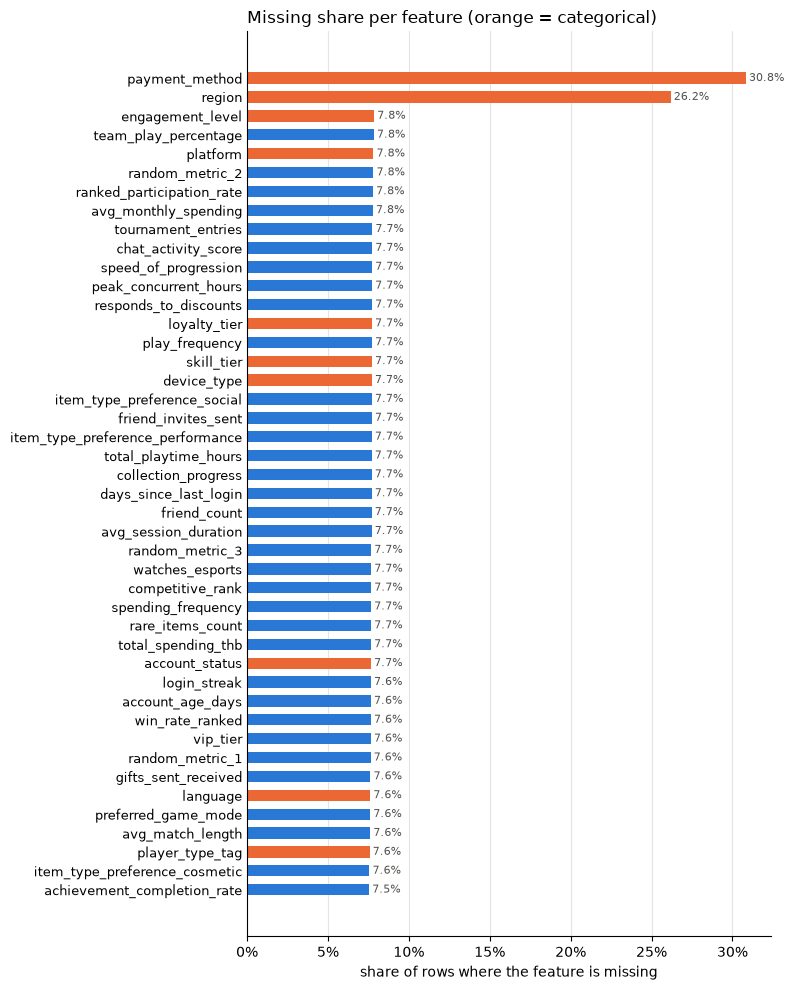

In [4]:
miss = tr[feats].isna()
share_missing = miss.mean().sort_values()
n_missing = miss.sum(axis=1).to_numpy()
print(f"share missing per feature: min {share_missing.min():.1%}, median {share_missing.median():.1%}, max {share_missing.max():.1%} | "
      f"rows with no missing value: {(n_missing == 0).mean():.1%}, mean missing per row {n_missing.mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(share_missing.index, share_missing.values, height=0.6,
        color=[ORANGE if c in cat_feats else BLUE for c in share_missing.index])
for name, v in share_missing.items():
    ax.text(v + 0.002, name, f"{v:.1%}", va='center', fontsize=8, color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('share of rows where the feature is missing')
ax.set_title('Missing share per feature (orange = categorical)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

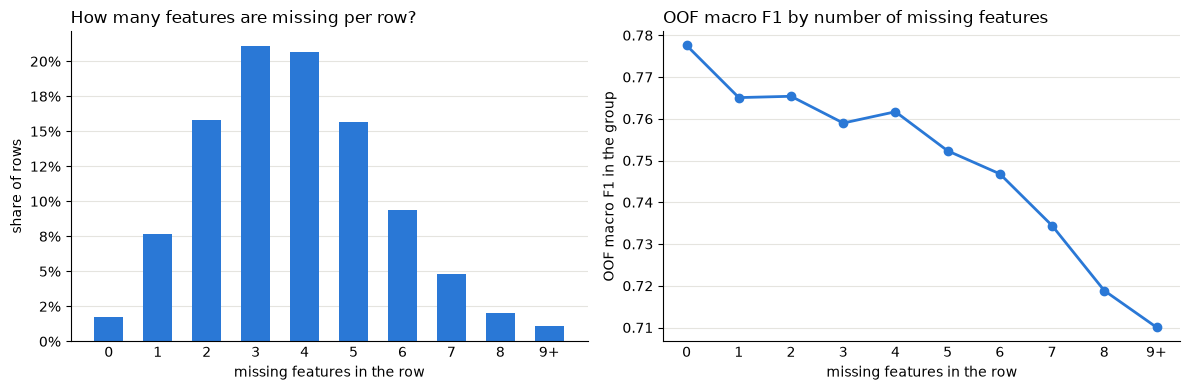

,rows,row_share,macro F1,Casual share,Grinder share,Social share,Whale share
missing features,,,,,,,
0,"1,846",1.8%,0.7776,41.6%,24.4%,19.4%,14.6%
1,"8,007",7.7%,0.7651,39.2%,24.7%,20.3%,15.8%
2,"16,461",15.8%,0.7654,39.7%,24.6%,20.2%,15.5%
3,"21,928",21.1%,0.7590,39.3%,25.0%,20.7%,15.0%
4,"21,496",20.7%,0.7617,39.1%,25.2%,20.2%,15.5%
5,"16,254",15.6%,0.7523,39.6%,25.0%,20.0%,15.5%
6,"9,780",9.4%,0.7468,39.2%,25.6%,20.0%,15.2%
7,"4,984",4.8%,0.7344,38.6%,25.8%,20.6%,15.0%
8,"2,121",2.0%,0.7188,39.5%,25.5%,19.1%,15.8%


In [5]:
group = np.minimum(n_missing, 9)
rows = []
for g in range(10):
    m = group == g
    rows.append({'missing features': '9+' if g == 9 else str(g), 'rows': int(m.sum()), 'row_share': m.mean(), 'macro F1': macro_f1(m),
                 **{f'{n} share': (y[m] == k).mean() for k, n in enumerate(NAMES)}})
by_count = pd.DataFrame(rows).set_index('missing features')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(by_count.index, by_count['row_share'], width=0.6, color=BLUE)
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.set_xlabel('missing features in the row'); a1.set_ylabel('share of rows')
a1.set_title('How many features are missing per row?', loc='left')
a1.tick_params(axis='x', length=0); tidy(a1)
a2.plot(by_count.index, by_count['macro F1'], marker='o', color=BLUE, linewidth=2)
a2.set_xlabel('missing features in the row'); a2.set_ylabel('OOF macro F1 in the group')
a2.set_title('OOF macro F1 by number of missing features', loc='left')
a2.tick_params(axis='x', length=0); tidy(a2)
plt.tight_layout()
plt.show()

(by_count.style
    .format({'rows': '{:,}', 'row_share': '{:.1%}', 'macro F1': '{:.4f}', **{f'{n} share': '{:.1%}' for n in NAMES}})
    .set_caption('OOF macro F1 and class mix by number of missing features per row'))

**NOTE:**


Every feature is missing in 7.5–7.8% of rows, except `region` (26%) and `payment_method` (31%). Only 1.8% of rows are complete, with 3.8 missing per row on average. Macro F1 falls from 0.778 on complete rows to 0.710 at 9+ missing, less steeply than in Task 1. The class mix is the same in every group.

## 2. Score by feature: missing vs present (+ random-group null)

แต่ละ feature เทียบ Macro F1 ของ OOF ในแถวที่ว่างกับแถวที่มีค่า และดูว่าสัดส่วนคลาสในแถวที่ว่างต่างจากแถวที่มีค่าไหม (chi-square: ถ้าต่าง การว่างบอก label ได้)

null: กลุ่มที่สุ่มจากทุกแถวขนาดเท่ากัน 2,000 ครั้ง `z` ติดลบ = แย่กว่ากลุ่มสุ่ม ทดสอบ 44 feature จึงใช้ Bonferroni p < 0.05 / 44 = 0.0011 (ไม่มีกลุ่มสุ่มไหนแย่ขนาดนั้นเลย)

In [6]:
rows = []
for c in feats:
    m = miss[c].to_numpy()
    counts = np.vstack([np.bincount(y[m], minlength=4), np.bincount(y[~m], minlength=4)])
    rows.append({'feature': c, 'kind': 'categorical' if c in cat_feats else 'numeric', 'rows_missing': int(m.sum()),
                 'row_share': m.mean(), 'class_mix_p': chi2_contingency(counts)[1],
                 'f1_missing': macro_f1(m), 'f1_present': macro_f1(~m)})
by_feat = pd.DataFrame(rows).set_index('feature')
by_feat['f1_gap'] = by_feat['f1_missing'] - by_feat['f1_present']

D = 2000
rng = np.random.default_rng(342)
sizes = by_feat['rows_missing'].to_numpy()
null_f1 = np.empty((D, len(feats)))
for d in range(D):
    rank = rng.permutation(len(y))  # one random ordering per draw; a group of size n is its first n rows
    for j, n in enumerate(sizes):
        null_f1[d, j] = macro_f1(rank < n)

obs = by_feat['f1_missing'].to_numpy()
low = (1 + (null_f1 <= obs).sum(0)) / (D + 1)
high = (1 + (null_f1 >= obs).sum(0)) / (D + 1)
by_feat['p'] = np.minimum(1, 2 * np.minimum(low, high))
by_feat['z'] = (obs - null_f1.mean(0)) / null_f1.std(0)
BONF = 0.05 / len(feats)
by_feat['sig'] = np.where(by_feat['p'] < BONF, np.where(by_feat['z'] < 0, 'worse', 'better'), '')
by_feat = by_feat.sort_values('z')

k95 = int(binom.ppf(0.95, len(feats), 0.05))
print(f"p < 0.05 (no correction): {(by_feat['p'] < 0.05).sum()} of {len(feats)} | chance alone: {len(feats) * 0.05:.1f} expected, up to {k95} in 95% of cases")
print(f"Bonferroni p < {BONF:.4f}: worse {(by_feat['sig'] == 'worse').sum()}, better {(by_feat['sig'] == 'better').sum()} (chance alone {len(feats) * BONF:.2f})")
print(f"class mix differs (chi-square p < {BONF:.4f}): {(by_feat['class_mix_p'] < BONF).sum()} features")

(by_feat.style
    .format({'rows_missing': '{:,}', 'row_share': '{:.1%}', 'class_mix_p': '{:.3f}', 'f1_missing': '{:.4f}', 'f1_present': '{:.4f}',
             'f1_gap': '{:+.4f}', 'p': '{:.4f}', 'z': '{:+.1f}'})
    .bar(subset='z', align=0, color=[RED, BLUE])
    .set_caption('OOF macro F1 where each feature is missing vs present, sorted by z'))

p < 0.05 (no correction): 8 of 44 | chance alone: 2.2 expected, up to 5 in 95% of cases
Bonferroni p < 0.0011: worse 3, better 0 (chance alone 0.05)
class mix differs (chi-square p < 0.0011): 0 features


,kind,rows_missing,row_share,class_mix_p,f1_missing,f1_present,f1_gap,p,z,sig
feature,,,,,,,,,,
loyalty_tier,categorical,"8,025",7.7%,0.648,0.6555,0.7649,-0.1094,0.0010,-20.9,worse
engagement_level,categorical,"8,162",7.8%,0.983,0.7290,0.7591,-0.0301,0.0010,-5.7,worse
total_playtime_hours,numeric,"8,007",7.7%,0.617,0.7384,0.7582,-0.0198,0.0010,-3.7,worse
vip_tier,numeric,"7,951",7.6%,0.491,0.7400,0.7581,-0.0181,0.0020,-3.4,
spending_frequency,numeric,"7,967",7.7%,0.914,0.7403,0.7581,-0.0178,0.0020,-3.4,
total_spending_thb,numeric,"7,965",7.7%,0.216,0.7470,0.7575,-0.0104,0.0480,-2.0,
account_age_days,numeric,"7,954",7.6%,0.362,0.7472,0.7575,-0.0102,0.0490,-1.9,
rare_items_count,numeric,"7,966",7.7%,0.596,0.7474,0.7575,-0.0100,0.0560,-1.9,
avg_session_duration,numeric,"8,001",7.7%,0.052,0.7483,0.7574,-0.0091,0.0870,-1.7,


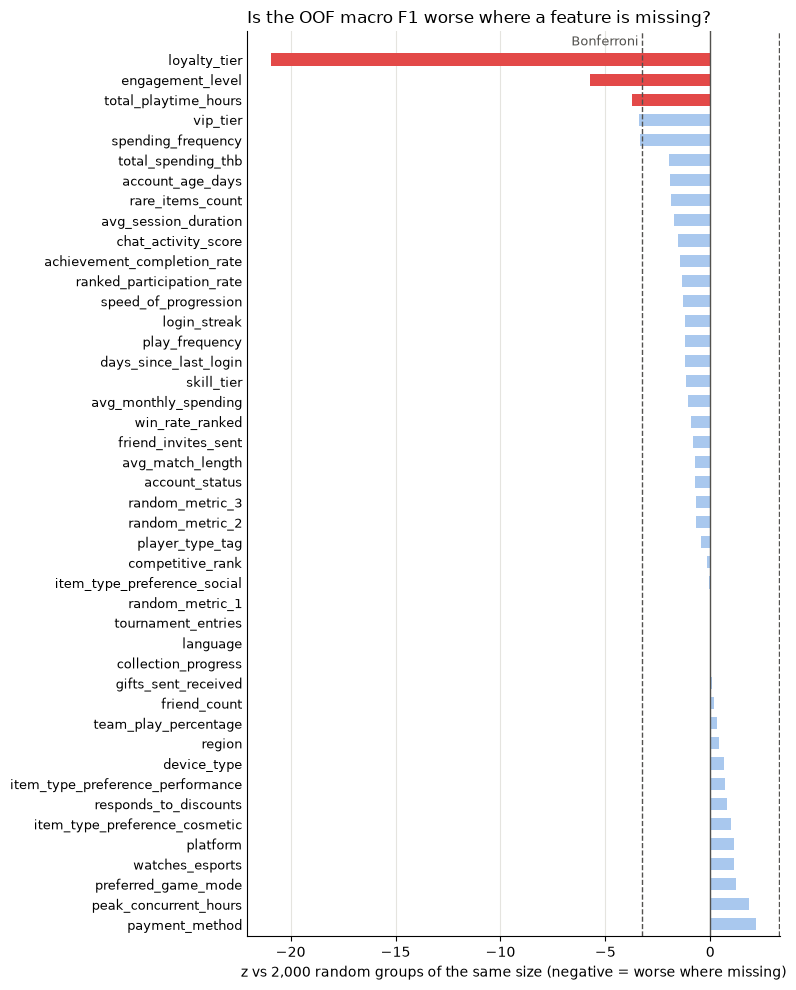

In [7]:
zz = by_feat.sort_values('z', ascending=False)
z_bonf = norm.ppf(1 - BONF / 2)
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(zz.index, zz['z'], height=0.6, color=[RED if s == 'worse' else BLUE if s == 'better' else '#a9c8ee' for s in zz['sig']])
for v in (-z_bonf, z_bonf):
    ax.axvline(v, color=INK, linestyle='--', linewidth=1)
ax.axvline(0, color=INK, linewidth=1)
ax.set_ylim(-0.6, len(zz) + 0.4)
ax.text(-z_bonf - 0.15, len(zz) - 0.45, 'Bonferroni', ha='right', va='bottom', fontsize=9, color=INK)
ax.set_xlabel('z vs 2,000 random groups of the same size (negative = worse where missing)')
ax.set_title('Is the OOF macro F1 worse where a feature is missing?', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


3 of 44 features have a real gap: `loyalty_tier` (F1 0.656 where missing vs 0.765, z −20.9), `engagement_level` (−0.030, z −5.7) and `total_playtime_hours` (−0.020, z −3.7). `vip_tier` and `spending_frequency` just miss the Bonferroni line (p 0.002). Without correction 8 features reach p < 0.05, while chance alone gives up to 5.

`loyalty_tier` alone matters a lot: 7.7% of rows lose 0.11 F1 when it is missing. No feature's missingness changes the class mix (chi-square), so a missing value carries no label information. `region` and `payment_method`, the features missing most often, cost nothing.

## 3. Can each feature be imputed? Label-free vs through the class

แต่ละ feature เทรน HistGradientBoosting 3-fold บนแถวที่มีค่า แล้ววัดแบบ out-of-fold: ตัวเลขใช้ R², binary ใช้ AUC, categorical หลายค่าใช้ macro one-vs-rest AUC

- **label-free**: ทายจาก feature อื่น 43 ตัว (ไม่ใช้ `segment`) = สิ่งที่การเติมค่าทำได้จริง
- **class only**: ทายจาก `segment` อย่างเดียว (R² = η², สัดส่วน variance ที่อธิบายด้วยคลาส; AUC จากตารางความถี่ต่อคลาส)
- **class + others**: ทายจาก `segment` + feature อื่น 43 ตัว **ใช้เพื่อทดสอบสมมติฐานเท่านั้น** ไม่ใช่วิธีเติมค่า

ถ้า feature เป็นอิสระต่อกันในแต่ละคลาส (conditional independence) จะได้ label-free ≤ class only และ class + others ≈ class only: feature อื่นบอกค่าของ feature นี้ได้ก็ผ่านการบอกคลาสเท่านั้น

In [8]:
X_all = tr[feats].copy()
for c in cat_feats:
    X_all[c] = X_all[c].astype('category')  # HistGradientBoosting uses pandas categories natively
seg = pd.Series(pd.Categorical(y), name='segment')


def kind_of(f):
    if f in cat_feats:
        return 'categorical' if tr[f].nunique() > 2 else 'binary'
    return 'binary' if tr[f].nunique() == 2 else 'numeric'


def oof_metric(X, t, kind):
    pr = np.zeros(len(t)) if kind == 'numeric' else np.zeros((len(t), t.nunique()))
    for a, b in KFold(3, shuffle=True, random_state=342).split(X):
        if kind == 'numeric':
            model = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], t.iloc[a])
            pr[b] = model.predict(X.iloc[b])
        else:
            model = HistGradientBoostingClassifier(random_state=342).fit(X.iloc[a], t.iloc[a])
            pr[b] = model.predict_proba(X.iloc[b])
    if kind == 'numeric':
        return r2_score(t, pr), spearmanr(t, pr)[0], model, b
    if kind == 'binary':
        return roc_auc_score(t, pr[:, 1]), np.nan, model, b
    return roc_auc_score(t, pr, multi_class='ovr', average='macro'), np.nan, model, b


def class_only(t, yk, kind):
    # In-sample: 4 class means (R² = eta²) or 4 class frequency tables -> AUC.
    if kind == 'numeric':
        means = t.groupby(yk).transform('mean')
        return r2_score(t, means)
    prob = pd.crosstab(yk, t, normalize='index').loc[yk].to_numpy()
    if kind == 'binary':
        return roc_auc_score(t, prob[:, 1])
    return roc_auc_score(t, prob, multi_class='ovr', average='macro', labels=sorted(t.unique()))


impute_rows = []
for f in feats:
    kind = kind_of(f)
    present = tr[f].notna().to_numpy()
    X = X_all.loc[present, [c for c in feats if c != f]].reset_index(drop=True)
    t = tr.loc[present, f].reset_index(drop=True)
    if kind != 'numeric':
        t = pd.Series(pd.Categorical(t.astype(str)).codes)  # integer codes 0..L-1 (sorted levels)
    yk = pd.Series(y[present])
    free, rho_free, model, b = oof_metric(X, t, kind)
    with_class, _, _, _ = oof_metric(pd.concat([X, seg[present].reset_index(drop=True)], axis=1), t, kind)
    scoring = 'r2' if kind == 'numeric' else 'roc_auc' if kind == 'binary' else 'roc_auc_ovr'
    pi = permutation_importance(model, X.iloc[b][:3000], t.iloc[b][:3000], n_repeats=2, random_state=342, scoring=scoring)
    top = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).head(3)
    impute_rows.append({'feature': f, 'kind': kind, 'metric': 'R²' if kind == 'numeric' else 'AUC', 'rows used': len(t),
                        'label-free': free, 'Spearman (label-free)': rho_free, 'class only': class_only(t, yk, kind),
                        'class + others': with_class,
                        'top predictors (drop)': ', '.join(f"{k} {v:.3f}" for k, v in top.items())})
imputation = pd.DataFrame(impute_rows).set_index('feature')
imputation['others add (beyond class)'] = imputation['class + others'] - imputation['class only']
imputation = imputation.sort_values(['metric', 'label-free'], ascending=[False, False])

num = imputation[imputation['metric'] == 'R²']
print(f"numeric: label-free R² max {num['label-free'].max():.3f} ({num['label-free'].idxmax()}), "
      f"features with R² > 0.3: {(num['label-free'] > 0.3).sum()} | label-free above class-only for "
      f"{(num['label-free'] > num['class only'] + 0.005).sum()} features | others add beyond class: max {imputation['others add (beyond class)'].max():+.3f}")
(imputation.style
    .format({'rows used': '{:,}', 'label-free': '{:.3f}', 'Spearman (label-free)': '{:.3f}', 'class only': '{:.3f}',
             'class + others': '{:.3f}', 'others add (beyond class)': '{:+.3f}'}, na_rep='')
    .set_caption('Imputability, 3-fold out-of-fold on rows where the feature is present (R² for numeric, AUC otherwise)'))

numeric: label-free R² max 0.115 (vip_tier), features with R² > 0.3: 0 | label-free above class-only for 0 features | others add beyond class: max +0.004


,kind,metric,rows used,label-free,Spearman (label-free),class only,class + others,top predictors (drop),others add (beyond class)
feature,,,,,,,,,
vip_tier,numeric,R²,"96,049",0.115,0.337,0.160,0.164,"loyalty_tier 0.140, spending_frequency 0.014, avg_monthly_spending 0.013",+0.004
spending_frequency,numeric,R²,"96,033",0.087,0.268,0.123,0.126,"loyalty_tier 0.092, avg_monthly_spending 0.012, vip_tier 0.010",+0.003
avg_monthly_spending,numeric,R²,"95,919",0.083,0.263,0.119,0.122,"loyalty_tier 0.088, vip_tier 0.011, spending_frequency 0.009",+0.003
rare_items_count,numeric,R²,"96,034",0.067,0.234,0.094,0.094,"loyalty_tier 0.070, vip_tier 0.012, spending_frequency 0.005",-0.000
days_since_last_login,numeric,R²,"95,995",0.061,0.243,0.112,0.110,"engagement_level 0.023, total_playtime_hours 0.008, avg_session_duration 0.006",-0.002
total_spending_thb,numeric,R²,"96,035",0.055,0.214,0.080,0.080,"loyalty_tier 0.062, rare_items_count 0.006, vip_tier 0.004",+0.000
total_playtime_hours,numeric,R²,"95,993",0.038,0.190,0.072,0.071,"engagement_level 0.020, days_since_last_login 0.006, tournament_entries 0.004",-0.001
friend_count,numeric,R²,"95,996",0.032,0.175,0.062,0.061,"engagement_level 0.020, gifts_sent_received 0.003, days_since_last_login 0.003",-0.002
friend_invites_sent,numeric,R²,"95,986",0.030,0.169,0.057,0.055,"engagement_level 0.018, days_since_last_login 0.013, total_playtime_hours 0.004",-0.002


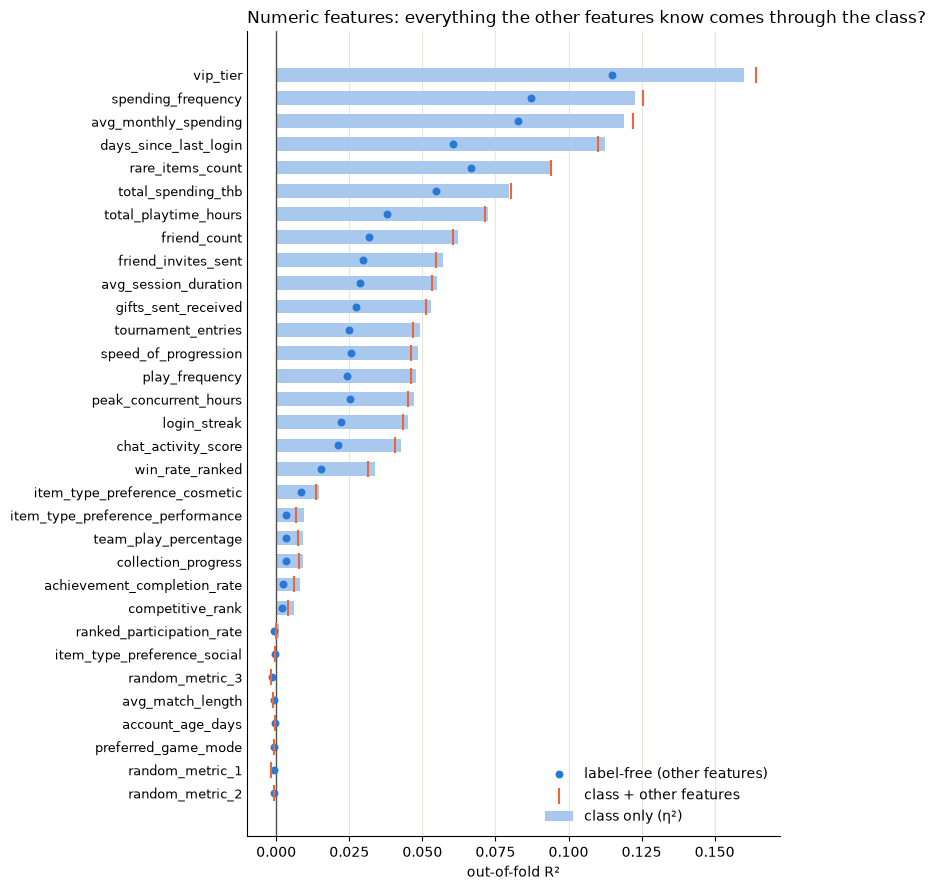

In [9]:
t = num.sort_values('class only')
yy = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(yy, t['class only'], height=0.6, color='#a9c8ee', label='class only (η²)')
ax.scatter(t['label-free'], yy, color=BLUE, s=22, zorder=3, label='label-free (other features)')
ax.scatter(t['class + others'], yy, color=ORANGE, marker='|', s=120, zorder=3, label='class + other features')
ax.set_yticks(yy, t.index)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel('out-of-fold R²')
ax.set_title('Numeric features: everything the other features know comes through the class?', loc='left')
ax.legend(frameon=False, loc='lower right')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


The README's claim holds. No numeric feature reaches R² 0.3 (max 0.115, `vip_tier`). For every numeric feature the label-free R² is below what the class alone explains (η²). Adding the other features to the class adds at most +0.004 (`vip_tier`), and usually nothing or slightly less (overfitting). The categoricals behave the same: `loyalty_tier` gets AUC 0.669 label-free, 0.738 from the class alone and 0.742 from both.

So the other features know a feature's value only through the class they point to. An imputed value would just be a function of the class posterior, which the model already computes, so imputation cannot add information. The top predictors fit this: `loyalty_tier` and `engagement_level`, the strongest class signals, predict almost everything else.

## 4. Correlation blocks

Spearman ของ feature ตัวเลข 34 ตัว (pairwise) เรียงด้วย hierarchical clustering แบบเดียวกับ Task 1 แล้วเทียบกับความสัมพันธ์ภายในแต่ละคลาส (README: สูงสุด 0.04)

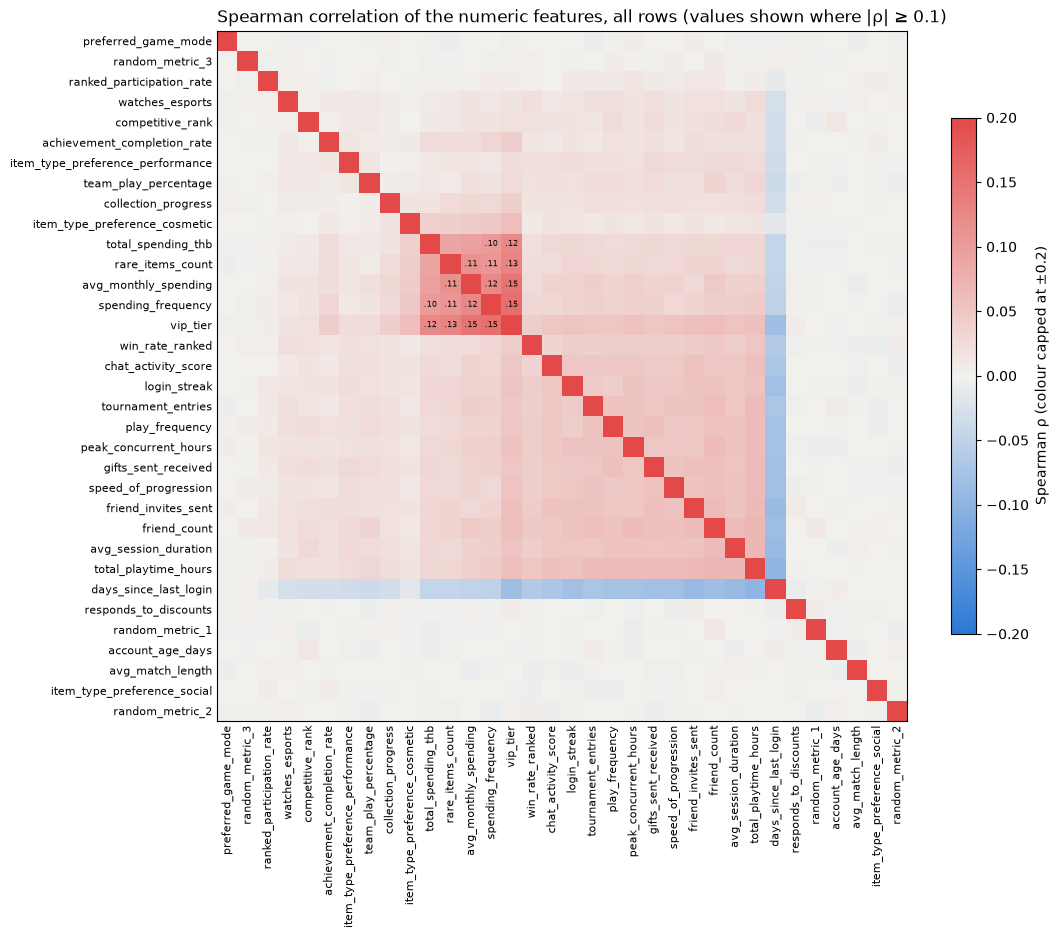

561 pairs of numeric features


,max |ρ|,pairs |ρ| ≥ 0.1,strongest pair
rows,,,
all rows,0.153,8,spending_frequency / vip_tier
Casual only,0.015,0,avg_session_duration / competitive_rank
Grinder only,0.023,0,days_since_last_login / friend_count
Social only,0.026,0,win_rate_ranked / achievement_completion_rate
Whale only,0.040,0,spending_frequency / vip_tier


In [10]:
num_feats = [c for c in feats if c not in cat_feats]
rho = tr[num_feats].corr(method='spearman')
Z = linkage(squareform(1 - rho.abs().to_numpy(), checks=False), 'average')
ordered = rho.index[leaves_list(Z)]
R = rho.loc[ordered, ordered]
off = np.abs(R.to_numpy()[~np.eye(len(R), dtype=bool)])
vmax = max(0.1, np.ceil(off.max() * 10) / 10)

cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f2f1ee', RED])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(R.to_numpy(), cmap=cmap, vmin=-vmax, vmax=vmax)
for i in range(len(R)):
    for j in range(len(R)):
        v = R.iat[i, j]
        if i != j and abs(v) >= 0.1:
            ax.text(j, i, f"{v:.2f}".replace('0.', '.'), ha='center', va='center', fontsize=6, color='#0b0b0b')
ax.set_xticks(range(len(R)), R.index, rotation=90, fontsize=8)
ax.set_yticks(range(len(R)), R.index, fontsize=8)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman ρ (colour capped at ±%.1f)' % vmax)
ax.set_title('Spearman correlation of the numeric features, all rows (values shown where |ρ| ≥ 0.1)', loc='left')
plt.tight_layout()
plt.show()

upper = np.triu(np.ones(rho.shape, bool), 1)
summary_rows = [{'rows': 'all rows', 'max |ρ|': off.max(), 'pairs |ρ| ≥ 0.1': int((np.abs(rho.to_numpy())[upper] >= 0.1).sum()),
                 'strongest pair': ' / '.join(rho.where(upper).abs().stack().idxmax())}]
for k, name in enumerate(NAMES):
    r_k = tr.loc[y == k, num_feats].corr(method='spearman')
    a = np.abs(r_k.to_numpy())[upper]
    summary_rows.append({'rows': f'{name} only', 'max |ρ|': a.max(), 'pairs |ρ| ≥ 0.1': int((a >= 0.1).sum()),
                         'strongest pair': ' / '.join(r_k.where(upper).abs().stack().idxmax())})
print(f"{upper.sum()} pairs of numeric features")
pd.DataFrame(summary_rows).set_index('rows').style.format({'max |ρ|': '{:.3f}'}).set_caption('Spearman: all rows vs inside each class')

**NOTE:**


There are no blocks. Over all rows the largest |ρ| is 0.153 (`spending_frequency` / `vip_tier`) and 8 of 561 pairs reach 0.1, all among spending and engagement features that the class drives. Inside each class the largest |ρ| is 0.015–0.040 and no pair reaches 0.1, the same as the README (0.04). The correlation seen over all rows comes from the class mix, not from links between features.

## 5. Naive Bayes vs CatBoost on missing values

naive Bayes ข้ามช่องที่ว่าง (ไม่นับเป็นหลักฐาน) ส่วน CatBoost ส่งค่าว่างเข้าต้นไม้ตรงๆ (ตัวเลข: NaN ไปทาง Min, หมวดหมู่: `__MISSING__`) ดูว่าสองโมเดลเสียคะแนนจากค่าว่างต่างกันไหม และนั่นอธิบายช่องว่างระหว่างแถวที่ครบกับแถวที่ว่างหลายช่องได้หรือเปล่า

- OOF แยกโมเดล: NB เทรนใหม่บน fold เดิม (deterministic) และ CatBoost โหลดจาก fold model ที่ `make_oof.py` บันทึกไว้ แล้วเช็คว่าผสมกลับได้ OOF เดิมพอดี
- **ทดลองลบค่า (MCAR):** ลบค่าเพิ่ม 3 ช่องในทุกแถวของ validation fold แล้วทายใหม่ด้วยโมเดลเดิม สุ่มเลือก feature ตามสัดส่วนค่าว่างจริง (`region`, `payment_method` ว่าง 26–31% จึงถูกเลือกบ่อยกว่า ถ้าสุ่มเท่ากันทุก feature จะลบ feature ที่มีสัญญาณบ่อยเกินจริง) ถ้าคะแนนตามจำนวนช่องที่ว่างรวมตรงกับของจริง แปลว่าค่าว่างจริงก็คือข้อมูลที่หายไปแบบสุ่ม ไม่มีอะไรให้กู้คืน
- **น้ำหนัก NB ตามจำนวนช่องที่ว่าง:** ถ้าสองโมเดลเสียคะแนนไม่เท่ากัน น้ำหนักที่ดีที่สุดอาจต่างกันตามกลุ่ม วัดแบบเลือกน้ำหนักบน 2 fold แล้ววัดบน fold ที่เหลือ

In [11]:
x, _, cats = _prepare(tr, tr.drop(columns='segment'), 'segment')  # the pipeline's CatBoost inputs (test arg only satisfies checks)
bayes_cols = [c for c in x.columns if not c.startswith('random_metric')]
bx = tr[bayes_cols]                                               # NB reads the raw columns, missing stays missing
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=342).split(x, y))
run_dir = Path('outputs/experiments/task2_missing_eda_run')

P_nb, P_cb = np.zeros_like(P), np.zeros_like(P)
nbs, cbs = [], []
for i, (a, b) in enumerate(folds, 1):
    nb = SmoothNaiveBayes().fit(bx.iloc[a], y[a])
    cb = CatBoostClassifier().load_model(str(run_dir / f'task2_fold{i}.cbm'))
    assert list(cb.classes_.astype(int)) == [0, 1, 2, 3]
    P_nb[b], P_cb[b] = nb.predict_proba(bx.iloc[b]), cb.predict_proba(x.iloc[b])
    nbs.append(nb); cbs.append(cb)
assert np.allclose(geometric_blend(P_cb, P_nb, TASK2_BAYES_WEIGHT), P, atol=1e-6), 'NB + CatBoost do not reproduce the saved OOF'

n_miss = tr[bayes_cols].isna().sum(axis=1).to_numpy()  # missing among the 41 model features (random_metric excluded)
bucket = pd.cut(n_miss, [-1, 0, 1, 2, 3, 4, 5, 6, 7, np.inf], labels=['0', '1', '2', '3', '4', '5', '6', '7', '8+'])
models = {'naive Bayes': P_nb, 'CatBoost': P_cb, 'blend (current)': P}
rows = []
for name, Q in models.items():
    q = Q.argmax(1)
    rows.append({'model': name, 'all rows': f1_score(y, q, average='macro'),
                 **{b: f1_score(y[bucket == b], q[bucket == b], average='macro') for b in bucket.categories}})
by_model = pd.DataFrame(rows).set_index('model')
by_model.loc['blend − CatBoost'] = by_model.loc['blend (current)'] - by_model.loc['CatBoost']
by_model.loc['NB − CatBoost'] = by_model.loc['naive Bayes'] - by_model.loc['CatBoost']
counts = pd.Series(bucket).value_counts().reindex(bucket.categories)
print('rows per bucket:', ', '.join(f"{k}: {v:,}" for k, v in counts.items()))
by_model.style.format('{:+.4f}', subset=pd.IndexSlice[['blend − CatBoost', 'NB − CatBoost'], :]) \
    .format('{:.4f}', subset=pd.IndexSlice[list(models), :]).set_caption('OOF macro F1 by number of missing model features')

rows per bucket: 0: 2,370, 1: 9,549, 2: 18,582, 3: 23,026, 4: 21,079, 5: 14,841, 6: 8,371, 7: 3,942, 8+: 2,240


,all rows,0,1,2,3,4,5,6,7,8+
model,,,,,,,,,,
naive Bayes,0.7564,0.7793,0.7642,0.7618,0.7609,0.7570,0.7523,0.7416,0.7367,0.7173
CatBoost,0.7516,0.7802,0.7597,0.7612,0.7582,0.7521,0.7471,0.7311,0.7214,0.6904
blend (current),0.7567,0.7814,0.7639,0.7636,0.7610,0.7578,0.7528,0.7395,0.7355,0.7129
blend − CatBoost,+0.0051,+0.0012,+0.0041,+0.0024,+0.0028,+0.0057,+0.0058,+0.0083,+0.0141,+0.0226
NB − CatBoost,+0.0047,-0.0009,+0.0045,+0.0006,+0.0026,+0.0049,+0.0052,+0.0104,+0.0153,+0.0269


all rows, 3 more values removed: NB 0.7564 -> 0.7371 (-0.0193) | CatBoost 0.7516 -> 0.7269 (-0.0247) | blend 0.7567 -> 0.7361 (-0.0206)


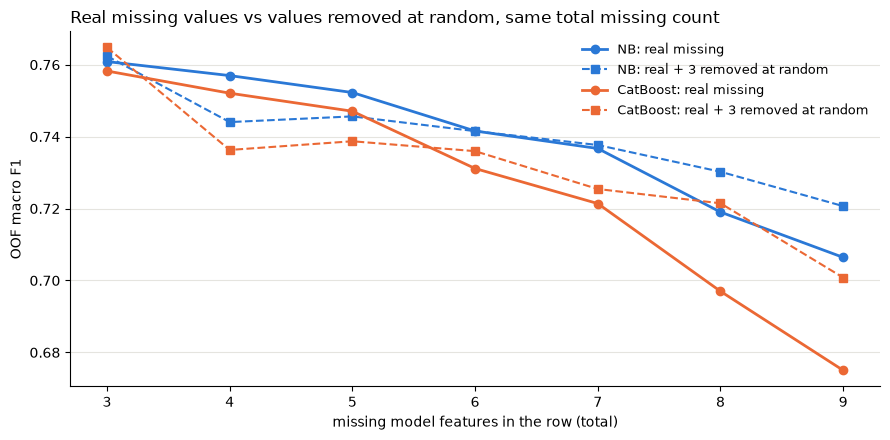

,rows real,rows masked,NB real,NB masked,CatBoost real,CatBoost masked,blend real,blend masked
missing (total),,,,,,,,
3,"23,026","2,370",0.7609,0.7624,0.7582,0.7648,0.7610,0.7644
4,"21,079","9,549",0.7570,0.7440,0.7521,0.7363,0.7578,0.7420
5,"14,841","18,582",0.7523,0.7456,0.7471,0.7387,0.7528,0.7454
6,"8,371","23,026",0.7416,0.7415,0.7311,0.7360,0.7395,0.7417
7,"3,942","21,079",0.7367,0.7377,0.7214,0.7254,0.7355,0.7363
8,"1,510","14,841",0.7190,0.7302,0.6970,0.7215,0.7171,0.7298
9,517,"8,371",0.7064,0.7207,0.6750,0.7008,0.6958,0.7176


In [12]:
K = 3  # extra values removed at random from every validation row
rng = np.random.default_rng(342)
known = tr[bayes_cols].notna().to_numpy()
weight = 1 - known.mean(axis=0)  # real missing share per feature: region / payment_method are picked ~4x as often
keys = np.where(known, rng.exponential(size=known.shape) / weight, np.inf)  # exponential race = weighted draw without replacement
drop = np.zeros_like(known)
drop[np.arange(len(drop))[:, None], np.argsort(keys, axis=1)[:, :K]] = True  # K present features per row

bx_m = bx.mask(drop)
x_m = x.copy()
for j, c in enumerate(bayes_cols):
    x_m.loc[drop[:, j], c] = '__MISSING__' if c in cats else np.nan

S_nb, S_cb = np.zeros_like(P), np.zeros_like(P)
for (a, b), nb, cb in zip(folds, nbs, cbs):
    S_nb[b], S_cb[b] = nb.predict_proba(bx_m.iloc[b]), cb.predict_proba(x_m.iloc[b])
S_bl = geometric_blend(S_cb, S_nb, TASK2_BAYES_WEIGHT)

n_after = n_miss + K
rows = []
for t_ in range(K, 11):
    obs_rows, sim_rows = n_miss == t_, n_after == t_
    if obs_rows.sum() < 200 or sim_rows.sum() < 200:
        continue
    row = {'missing (total)': t_, 'rows real': int(obs_rows.sum()), 'rows masked': int(sim_rows.sum())}
    for name, Q, S in (('NB', P_nb, S_nb), ('CatBoost', P_cb, S_cb), ('blend', P, S_bl)):
        row[f'{name} real'] = f1_score(y[obs_rows], Q[obs_rows].argmax(1), average='macro')
        row[f'{name} masked'] = f1_score(y[sim_rows], S[sim_rows].argmax(1), average='macro')
    rows.append(row)
mask_test = pd.DataFrame(rows).set_index('missing (total)')
overall = {name: (f1_score(y, Q.argmax(1), average='macro'), f1_score(y, S.argmax(1), average='macro'))
           for name, Q, S in (('NB', P_nb, S_nb), ('CatBoost', P_cb, S_cb), ('blend', P, S_bl))}
print(f"all rows, {K} more values removed: " + ' | '.join(f"{k} {a:.4f} -> {b:.4f} ({b - a:+.4f})" for k, (a, b) in overall.items()))

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, colour in (('NB', BLUE), ('CatBoost', ORANGE)):
    ax.plot(mask_test.index, mask_test[f'{name} real'], marker='o', color=colour, linewidth=2, label=f'{name}: real missing')
    ax.plot(mask_test.index, mask_test[f'{name} masked'], marker='s', color=colour, linewidth=1.5, linestyle='--',
            label=f'{name}: real + {K} removed at random')
ax.set_xlabel('missing model features in the row (total)')
ax.set_ylabel('OOF macro F1')
ax.set_title('Real missing values vs values removed at random, same total missing count', loc='left')
ax.legend(frameon=False, fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()
mask_test.style.format('{:.4f}').format('{:,}', subset=['rows real', 'rows masked']).set_caption('Real vs randomly removed values, same total missing count')

In [13]:
W = np.round(np.arange(0, 1.01, 0.1), 1)
grp = pd.cut(n_miss, [-1, 2, 4, 6, np.inf], labels=['0-2', '3-4', '5-6', '7+']).astype(str)
blends = {w: geometric_blend(P_cb, P_nb, w).argmax(1) for w in W}

# In-sample view: best NB weight per group (optimistic).
rows = []
for g in ['0-2', '3-4', '5-6', '7+']:
    m = grp == g
    f = {w: f1_score(y[m], blends[w][m], average='macro') for w in W}
    best = max(f, key=f.get)
    rows.append({'group': g, 'rows': int(m.sum()), 'F1 at 0.6': f[0.6], 'best weight': best, 'F1 at best': f[best], 'gain': f[best] - f[0.6]})
per_group = pd.DataFrame(rows).set_index('group')

# Honest view: choose each group's weight on 2 folds, score the 3rd fold.
fold_of = np.zeros(len(y), int)
for i, (_, b) in enumerate(folds):
    fold_of[b] = i
honest = np.zeros(len(y), int)
for i in range(3):
    fit, ev = fold_of != i, fold_of == i
    for g in per_group.index:
        mf, me = fit & (grp == g), ev & (grp == g)
        w = max(W, key=lambda w: f1_score(y[mf], blends[w][mf], average='macro'))
        honest[me] = blends[w][me]
f1_honest = f1_score(y, honest, average='macro')
print(f"global NB weight 0.6: {f1_all:.4f} | NB weight per missing group, chosen on 2 folds and scored on the 3rd: "
      f"{f1_honest:.4f} ({f1_honest - f1_all:+.4f})")
per_group.style.format({'rows': '{:,}', 'F1 at 0.6': '{:.4f}', 'best weight': '{:.1f}', 'F1 at best': '{:.4f}', 'gain': '{:+.4f}'}) \
    .set_caption('Best NB weight per missing-count group (in-sample, optimistic)')

global NB weight 0.6: 0.7567 | NB weight per missing group, chosen on 2 folds and scored on the 3rd: 0.7562 (-0.0005)


,rows,F1 at 0.6,best weight,F1 at best,gain
group,,,,,
0-2,"30,501",0.7651,0.6,0.7651,+0.0000
3-4,"44,105",0.7595,0.6,0.7595,+0.0000
5-6,"23,212",0.7481,1.0,0.7484,+0.0004
7+,"6,182",0.7275,1.0,0.7298,+0.0023


**NOTE:**


The gap between naive Bayes and CatBoost comes from rows with many missing values. On complete rows CatBoost is as good as naive Bayes (0.780 vs 0.779). From 4 missing on, NB pulls ahead, by +0.027 at 8+. With 3 more values removed at random, CatBoost loses 0.025 and NB 0.019. This is the expected pattern: when features are independent within a class, skipping a missing value is the exact Bayes answer. CatBoost instead sends a missing value down a learned branch and gets less out of the remaining features.

At the same total missing count, real and randomly removed values give the same F1 within about ±0.015, with no consistent direction (the real groups at 8–9 missing are small). That fits values missing at random: the drop is information that is simply not there.

The current blend already collects NB's advantage: it beats CatBoost by +0.023 at 8+ missing. Choosing the NB weight per missing-count group adds +0.0023 in-sample in the 7+ group, but chosen on 2 folds and scored on the 3rd it gives −0.0005 overall. The fixed weight 0.6 is already right.

## Summary

- **OOF:** Macro F1 0.7567 ตรงกับ README แถวเรียงตรงกับ `train.csv` แยกโมเดลได้ (NB 0.7564, CatBoost 0.7516) และผสมกลับได้ OOF เดิมพอดี
- **ค่าว่าง:** ทุก feature ว่าง ~7.7% ยกเว้น `region` 26% และ `payment_method` 31% แถวครบ 1.8% Macro F1 ตกจาก 0.778 (ครบ) ถึง 0.710 (ว่าง 9+ ช่อง) สัดส่วนคลาสเท่ากันทุกกลุ่ม
- **Gap ต่อ feature:** significant 3 ตัว: `loyalty_tier` (0.656 เทียบกับ 0.765, z −20.9), `engagement_level`, `total_playtime_hours` การว่างของ feature ไหนก็ไม่เปลี่ยนสัดส่วนคลาส
- **เติมค่า:** ไม่มี feature ไหนเติมได้ R² สูงสุด 0.115 (`vip_tier`) และ `loyalty_tier` AUC 0.669 ทุกตัวได้น้อยกว่าที่คลาสอย่างเดียวอธิบายได้ และ feature อื่นบอกเพิ่มจากคลาสได้ไม่เกิน +0.004
- **บล็อก:** ไม่มี ความสัมพันธ์ภายในคลาสสูงสุด 0.040 (ตรงกับ README) ที่เห็นทั้งหมดสูงสุด 0.153 มาจากคลาสล้วนๆ
- **NB vs CatBoost:** ข้อได้เปรียบของ NB อยู่ในแถวที่ว่างหลายช่อง (ครบ: ใกล้กัน, ว่าง 8+: NB ดีกว่า +0.027) เพราะเมื่อ feature อิสระกันในคลาส การข้ามค่าว่างคือคำตอบที่ถูกต้องตาม Bayes พอดี blend ตอนนี้ได้ส่วนนี้ไปแล้ว การปรับน้ำหนัก NB ตามจำนวนช่องที่ว่างวัดแบบแยกชุดได้ −0.0005

**Decision: ไม่มีการทดลองเรื่องค่าว่างสำหรับ Task 2**

| เกณฑ์ | ผล | ผ่านไหม |
|---|---|---|
| OOF แย่ลงจริงในแถวที่ feature ว่าง (Bonferroni) | 3 feature | ผ่าน |
| เติมค่าได้ (R² > 0.3) | R² สูงสุด 0.115, `loyalty_tier` AUC 0.669 | ไม่ผ่าน |
| feature อื่นบอกค่าได้มากกว่าที่คลาสบอก | สูงสุด +0.004 | ไม่ผ่าน |
| ปรับวิธีรวมโมเดลตามค่าว่าง | −0.0005 (เลือกบน 2 fold วัดบน fold ที่ 3) | ไม่ผ่าน |

ยืนยันสมมติฐานใน README ด้วยตัวเลข: feature อิสระต่อกันในแต่ละคลาส ข้อมูลที่หายไปพร้อมค่าว่าง (เช่น `loyalty_tier`) จึงไม่มีอยู่ใน feature อื่นเลย นอกจากผ่านคลาสที่โมเดลคำนวณอยู่แล้ว naive Bayes ที่ข้ามค่าว่างจึงเป็นวิธีที่ถูกต้องแล้ว ทางนี้ไม่มีอะไรเหลือให้เก็บ